# CARNIVAL causal network inference

> **AMBIENTES CONDA**
> - scRNA_NEW_signaling

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import scanpy as sc
import pandas as pd
import numpy as np

import corneto as cn
import omnipath as op
from omnipath import interactions
from corneto.graph import Graph
from corneto.methods.future.carnival import CarnivalFlow

DATASET = "Ffar2"
normal_condition="WT"
compare_condition="KO"

versao = f"09sx.scNeu{DATASET}"

stage_order=["G0","G1","G2","G3","G4","G5a","G5b","G5c"]


celltype_col="celltype"
condition_col="condition"
sample_col="sample"
id_col="sample"
counts_layer="QC_filtered"
design_col="condition"

out_dir = Path(f"/media/tahila/DADOS/HD/2605_scNeu/scNeu{DATASET}")
out_dir.mkdir(exist_ok=True)

nets_out_dir = Path(f"{out_dir}/{versao}_nets/carnival")
nets_out_dir.mkdir(exist_ok=True, parents=True)


CARNIVAL was used to infer signaling networks that could connect the loss of
FFAR2 activity to the observed changes in transcription factor activity.

Because the perturbation target is known, the analysis follows the Standard
CARNIVAL formulation (StdCARNIVAL), in which a known perturbation is propagated
through a signed and directed prior knowledge network (PKN) toward measured
downstream nodes [Liu, 2019].

The analysis was defined using the **KO versus WT** contrast. Therefore, the
FFAR2 knockout was represented as an inhibitory perturbation:

`Ffar2 = -1`

Transcription factors were used as downstream measurements. Their activity
scores represent the differential activity in KO relative to WT:

- positive score: higher TF activity in KO;
- negative score: lower TF activity in KO.

CARNIVAL discretizes the direction of the measurements to formulate the causal
constraints of the integer linear programming (ILP) problem, while the
continuous activity values contribute to the weighting of measurement mismatch
in the objective function [Melas, 2015; Liu, 2019].

The original differential TF activity scores were preserved at this stage.
No arbitrary rescaling was applied because the magnitude of the measurement
scores contributes to the balance between measurement agreement and network
complexity in the CARNIVAL optimization [Liu, 2019].## CARNIVAL causal network inference

CARNIVAL was used to infer signaling networks that could connect the loss of
FFAR2 activity to the observed changes in transcription factor activity.

Because the perturbation target is known, the analysis follows the Standard
CARNIVAL formulation (StdCARNIVAL), in which a known perturbation is propagated
through a signed and directed prior knowledge network (PKN) toward measured
downstream nodes [Liu, 2019].

The analysis was defined using the **KO versus WT** contrast. Therefore, the
FFAR2 knockout was represented as an inhibitory perturbation:

`Ffar2 = -1`

Transcription factors were used as downstream measurements. Their activity
scores represent the differential activity in KO relative to WT:

- positive score: higher TF activity in KO;
- negative score: lower TF activity in KO.

CARNIVAL discretizes the direction of the measurements to formulate the causal
constraints of the integer linear programming (ILP) problem, while the
continuous activity values contribute to the weighting of measurement mismatch
in the objective function [Melas, 2015; Liu, 2019].

The original differential TF activity scores were preserved at this stage.
No arbitrary rescaling was applied because the magnitude of the measurement
scores contributes to the balance between measurement agreement and network
complexity in the CARNIVAL optimization [Liu, 2019].

# 1. CARNIVAL input preparation



CARNIVAL was used to infer signaling events that could connect the loss of FFAR2 function to downstream changes in transcription factor activity.

Because the perturbation target is known, the analysis follows the Standard CARNIVAL formulation (StdCARNIVAL), which uses a known perturbation together with downstream measurements and a signed, directed prior knowledge network (PKN) [Melas, 2015; Liu, 2019].

The comparison was defined as **KO versus WT**. Therefore, loss of FFAR2 function was represented as an inhibitory perturbation:

`Ffar2 = -1`

The selected transcription factors were used as downstream measurements. Each TF must have a signed continuous differential activity score representing:

`KO - WT`

Therefore:

* `score > 0`: higher TF/regulon activity in KO;
* `score < 0`: lower TF/regulon activity in KO;
* `score = 0`: no directional differential activity.

CARNIVAL internally discretizes the direction of the measurements when constructing the ILP constraints, while the magnitude of the continuous measurements contributes to the measurement-specific mismatch penalty in the objective function [Liu, 2019]. Therefore, the original signed activity scores were preserved without converting them to binary values or absolute values.

The original CARNIVAL study used TF activities inferred mainly with DoRothEA/VIPER. Here, SCENIC/ULM-derived differential regulon activities are used as downstream measurements. This represents a methodological adaptation and the resulting TF constraints are interpreted as differential regulon activity rather than as direct measurements of TF protein activity.


## TFs and source input

In [2]:
tf_table = pd.read_csv(f"{nets_out_dir}/{versao}_active_TRIs_SCENIC_ULM.tsv", sep="\t")
tf_table

,source_TF,target_DEG,celltype,effect,mean_%cells_SCENIC,TF_ulm_score,TF_ulm_padj,log2FoldChange_DEG
0,Rara,Dusp1,G4,stimulation,99.759492,3.044276,1.308446e-02,0.868976
1,Rara,Fos,G4,stimulation,99.759492,3.044276,1.308446e-02,0.764895
2,Rara,Il1b,G4,stimulation,99.759492,3.044276,1.308446e-02,1.692421
3,Fos,Fos,G4,inhibition,99.657668,3.173471,9.647506e-03,0.764895
4,Fos,Il1b,G4,stimulation,99.657668,3.173471,9.647506e-03,1.692421
5,Fos,Jund,G4,inhibition,99.657668,3.173471,9.647506e-03,0.538892
6,Fos,Plaur,G4,stimulation,99.657668,3.173471,9.647506e-03,0.385295
7,Irf5,Il1b,G4,stimulation,99.078655,4.119231,3.825578e-04,1.692421
8,Junb,Il1b,G5a,stimulation,99.010240,5.251073,1.370904e-05,0.984280
9,Jund,Il1b,G5a,stimulation,98.195302,5.732284,1.232601e-06,0.984280


In [3]:
perturbations = {
    "FFAR2": -1
}

In [4]:
import numpy as np
import pandas as pd


def BuildCarnivalMeasurements(
    tf_table: pd.DataFrame,
    *,
    celltype: str | None = None,
    tf_col: str = "source_TF",
    score_col: str = "TF_ulm_score",
    celltype_col: str = "celltype",
) -> dict[str, float]:
    """
    Build CARNIVAL TF measurements from a TF-target table.

    Parameters
    ----------
    tf_table : pd.DataFrame --> Table containing TFs and signed activity scores.
    celltype : str | None --> Cell type to select before building measurements.
    tf_col : str --> Column containing TF identifiers.
    score_col : str --> Column containing signed differential TF activity scores.
    celltype_col : str --> Column containing cell-type labels.

    Returns
    -------
    measurements : dict[str, float] --> TF-to-activity dictionary for CARNIVAL.
    """

    df = tf_table.copy()

    # Select cell type
    if celltype is not None:
        df = df.loc[df[celltype_col] == celltype].copy()

        if df.empty:
            raise ValueError(f"No rows found for celltype='{celltype}'.")

    # Select TF activity
    df = df[[tf_col, score_col]].dropna().copy()
    df[score_col] = pd.to_numeric(df[score_col], errors="raise")

    if not np.isfinite(df[score_col]).all():
        raise ValueError(f"{score_col} contains non-finite values.")

    # Check conflicting scores
    n_scores = df.groupby(tf_col)[score_col].nunique()

    conflicting = n_scores[n_scores > 1].index.tolist()

    if conflicting:
        raise ValueError(
            f"TFs with multiple activity scores: {conflicting}. "
            "Select one cell type or resolve the scores first."
        )

    # Remove repeated TF-target rows
    df = df.drop_duplicates(subset=tf_col)

    return dict(zip(df[tf_col], df[score_col].astype(float)))

In [5]:
celltype_measurements = {celltype: BuildCarnivalMeasurements(tf_table, celltype=celltype) for celltype in tf_table[celltype_col].unique()}
all_tfs = tf_table["source_TF"].unique().tolist()
all_tfs

['Rara',
 'Fos',
 'Irf5',
 'Junb',
 'Jund',
 'Fosl2',
 'Cebpb',
 'Irf1',
 'Cebpd',
 'Atf3',
 'Stat1',
 'Stat2',
 'Maz']

## PKN input

In [2]:
def BuildCarnivalPknFromOmniPath(ppi_df: pd.DataFrame) -> pd.DataFrame:
    """
    Converte o DataFrame do OmniPath (com colunas consensus_*) para uma PKN no formato do CARNIVAL:
    source, target, sign (1/-1).
    based in https://github.com/saezlab/transcriptutorial/tree/master/scripts
    """

    required = {
        "source", "target",
        "is_directed",
        "consensus_direction",
        "consensus_stimulation",
        "consensus_inhibition",
    }
    missing = required - set(ppi_df.columns)
    if missing:
        raise ValueError(f"Faltam colunas necessárias: {sorted(missing)}")

    # 1) manter apenas interações direcionadas e com direção consensual
    df = ppi_df.loc[
        (ppi_df["is_directed"] == True) &
        (ppi_df["consensus_direction"] == True)
    ].copy()

    # 2) manter apenas as que têm sinal consensual (stimulation XOR inhibition)
    df = df.loc[
        (df["consensus_stimulation"] == True) ^ (df["consensus_inhibition"] == True)
    ].copy()

    # 3) criar a coluna sign (+1 / -1)
    df["sign"] = np.where(df["consensus_stimulation"] == True, 1, -1)

    # 4) montar PKN final
    pkn = (
        df[["source", "sign", "target"]]
        .dropna()
        .drop_duplicates()
        .reset_index(drop=True)
    )

    return pkn

In [7]:
# PPI curada (dataset "omnipath") – só interações bibliograficamente suportadas
ppi_df = interactions.OmniPath.get(
    organism='mouse',
    genesymbols=True,
    fields=['curation_effort','references', 'sources']
)

ppi_df = ppi_df.drop(columns=['source','target'])
ppi_df.rename(columns={"source_genesymbol": "source", "target_genesymbol": "target"}, inplace=True)

pkn = BuildCarnivalPknFromOmniPath(ppi_df)
#pkn.to_csv("omnpath_mouse_pkn_carnival.tsv", sep="\t", index=False)

# pkn: DataFrame com colunas ['source','target','sign'] (sign = +1/-1)
tuples = list(zip(pkn["source"], pkn["sign"].astype(int), pkn["target"]))

graph = Graph.from_tuples(tuples)

tuples[:5]

[('Calm1', -1, 'B2RPS7'),
 ('Cav1', 1, 'B2RPS7'),
 ('Drd2', 1, 'B2RPS7'),
 ('Mdfi', -1, 'B2RPS7'),
 ('Itpr2', 1, 'B2RPS7')]

### CHECK IF ALL TFs ARE CONTAINED IN THE PKN

Here, we need to check if the TFs are in the PKN from mouse. Otherwise, we will decide if we get the human one.

In [8]:
graph_nodes = set(graph.V)

tf_in_pkn = pd.DataFrame({
    "TF": all_tfs,
    "in_pkn": [tf in graph_nodes for tf in all_tfs],
})

tf_in_pkn

,TF,in_pkn
0,Rara,True
1,Fos,True
2,Irf5,True
3,Junb,True
4,Jund,True
5,Fosl2,False
6,Cebpb,True
7,Irf1,True
8,Cebpd,True
9,Atf3,True


Here we see that a lot of TFs are not in the mouse PKN.  
Let test the human one.

In [3]:
from omnipath import interactions

# Curated human PPI from the OmniPath dataset
ppi_df = interactions.OmniPath.get(
    organism="human",
    genesymbols=True,
    fields=["curation_effort", "references", "sources"],
)

# Use gene symbols instead of UniProt IDs
ppi_df = ppi_df.drop(columns=["source", "target"])
ppi_df = ppi_df.rename(
    columns={
        "source_genesymbol": "source",
        "target_genesymbol": "target",
    }
)

# Build signed and directed CARNIVAL PKN
pkn = BuildCarnivalPknFromOmniPath(ppi_df)

# Optional export
pkn.to_csv(
     "/home/tahila/0.resources/omnipath/omnipath_human_pkn_carnival.tsv",
     sep="\t",
     index=False,
 )

# Build CORNETO graph
tuples = list(
    zip(
        pkn["source"],
        pkn["sign"].astype(int),
        pkn["target"],
    )
)

graph = Graph.from_tuples(tuples)

OSError: Cannot save file into a non-existent directory: '/home/tahila/0.resources/omnipath'

In [5]:
ppi_df.to_csv("/home/tahila/0.resources/databases/omnipath/omnipath_human_ppi.tsv", sep="\t")

In [10]:
graph_nodes = set(graph.V)
all_tfs_up = [a.upper() for a in all_tfs]+["FFAR2"]

tf_in_pkn = pd.DataFrame({
    "TF": all_tfs_up,
    "in_pkn": [tf in graph_nodes for tf in all_tfs_up],
})

tf_in_pkn

,TF,in_pkn
0,RARA,True
1,FOS,True
2,IRF5,True
3,JUNB,True
4,JUND,True
5,FOSL2,False
6,CEBPB,True
7,IRF1,True
8,CEBPD,True
9,ATF3,True


There are more in the human one, so lets use that.  
Below, we will convert to the ortholog correspondence, in order to keep it robust, instead of only transform in uppercase.

In [11]:
from gprofiler import GProfiler
import pandas as pd


def MapMouseHumanOrthologs(
    genes: list[str],
) -> tuple[pd.DataFrame, dict[str, str]]:
    """
    Map mouse genes to reciprocal unique human orthologs using g:Profiler.

    Parameters
    ----------
    genes : list[str] --> Mouse gene symbols to map.

    Returns
    -------
    orthologs : pd.DataFrame --> Reciprocal unique mouse-human gene mappings.
    ortholog_map : dict[str, str] --> {mouse: human}, same mapping as
        `orthologs`, ready to use with e.g. `.map()`/`.replace()`.
    """

    gp = GProfiler(return_dataframe=True)

    # Mouse -> human
    forward = gp.orth(
        organism="mmusculus",
        query=genes,
        target="hsapiens",
    )

    forward = (
        forward[["incoming", "name"]]
        .dropna()
        .rename(columns={"incoming": "mouse", "name": "human"})
        .drop_duplicates()
    )

    # Keep unique forward mappings
    n_human = forward.groupby("mouse")["human"].nunique()
    forward = forward[
        forward["mouse"].isin(n_human[n_human == 1].index)
    ].copy()

    # Human -> mouse
    reverse = gp.orth(
        organism="hsapiens",
        query=forward["human"].unique().tolist(),
        target="mmusculus",
    )

    reverse = (
        reverse[["incoming", "name"]]
        .dropna()
        .rename(columns={"incoming": "human", "name": "mouse_reverse"})
        .drop_duplicates()
    )

    # Keep unique reverse mappings
    n_mouse = reverse.groupby("human")["mouse_reverse"].nunique()
    reverse = reverse[
        reverse["human"].isin(n_mouse[n_mouse == 1].index)
    ].copy()

    # Require reciprocal mapping
    orthologs = forward.merge(reverse, on="human")

    orthologs = orthologs.loc[
        orthologs["mouse"] == orthologs["mouse_reverse"],
        ["mouse", "human"],
    ].reset_index(drop=True)

    ortholog_map = dict(zip(orthologs["mouse"], orthologs["human"]))

    return orthologs, ortholog_map

In [12]:
genes_to_map = list(perturbations) + list(all_tfs)

orthologs, ortholog_map = MapMouseHumanOrthologs(genes_to_map)

display(orthologs)

,mouse,human
0,Rara,RARA
1,Fos,FOS
2,Irf5,IRF5
3,Junb,JUNB
4,Jund,JUND
5,Fosl2,FOSL2
6,Cebpb,CEBPB
7,Irf1,IRF1
8,Cebpd,CEBPD
9,Atf3,ATF3


In [13]:
celltype_measurements_human = {
    celltype: {
        ortholog_map[tf]: score
        for tf, score in measurements.items()
        if tf in ortholog_map
    }
    for celltype, measurements in celltype_measurements.items()
}
measurements_G4 = celltype_measurements_human["G4"]
celltype_measurements_human

{'G4': {'RARA': 3.044276032183396,
  'FOS': 3.173470549035915,
  'IRF5': 4.119231462369839,
  'FOSL2': 3.5505711001217466,
  'CEBPB': 2.836367782793344,
  'JUND': 7.501391837728253,
  'JUNB': 7.268205362238173,
  'CEBPD': 3.0937904186394203,
  'ATF3': 4.117894025257808,
  'IRF1': 3.1112516961140675,
  'STAT1': 7.820997249773264,
  'STAT2': 4.503760323555568,
  'MAZ': 2.5748472181155604},
 'G5a': {'JUNB': 5.251072853423797,
  'JUND': 5.732283571066902,
  'IRF1': 2.810192626790563,
  'STAT1': 6.95073121783906},
 'G3': {'RARA': 3.1110020550358737}}

# 3. Check PKN reachability

Before CARNIVAL optimization, the PKN was evaluated to determine which
transcription factor measurements could be reached from the FFAR2 perturbation.

Only nodes located on directed paths connecting the perturbation to downstream
measurements can contribute to the inferred signaling network. Therefore,
TFs not reachable from FFAR2 were identified before optimization.

This analysis evaluates **topological and directional reachability** in the PKN.
It does not determine whether the activation/inhibition signs along a path are
consistent with the observed TF activity. Sign consistency is evaluated later
during the CARNIVAL optimization.

An unreachable TF should therefore be interpreted as a limitation of the
available prior knowledge network rather than evidence that FFAR2 cannot
biologically regulate that TF [Liu, 2019; Rodriguez-Mier, 2025].

In [14]:
def CheckCarnivalReachability(
    graph,
    perturbations: dict[str, float],
    measurements: dict[str, float],
) -> tuple[pd.DataFrame, object]:
    """
    Check directed reachability between CARNIVAL inputs and outputs.

    Parameters
    ----------
    graph : cn.Graph --> CORNETO prior knowledge network.
    perturbations : dict[str, float] --> Upstream perturbation values.
    measurements : dict[str, float] --> Downstream TF activity measurements.

    Returns
    -------
    report : pd.DataFrame --> One row per measurement TF, with `in_pkn`
        (present as a graph node at all) and `reachable` (directed path
        from at least one perturbation -- only meaningful when `in_pkn`
        is True, False otherwise).
    pruned_graph : cn.Graph --> PKN restricted to input-to-output directed
        paths, built only from the perturbation/measurement nodes that
        are actually present in `graph`.
    """
    graph_nodes = set(graph.V)

    # not every perturbation/measurement node is guaranteed to exist in
    # the PKN (e.g. a differentially active TF with no curated directed
    # OmniPath interaction) -- graph.prune() raises a raw KeyError on a
    # missing node instead of skipping it, so filter first
    inputs = set(perturbations) & graph_nodes
    outputs = set(measurements) & graph_nodes

    # Keep directed input-to-output paths
    pruned_graph = graph.prune(inputs, outputs)
    reachable = set(pruned_graph.V)

    report = pd.DataFrame({
        "TF": list(measurements),
        "score": list(measurements.values()),
    })

    report["in_pkn"] = report["TF"].isin(graph_nodes)
    report["reachable"] = report["in_pkn"] & report["TF"].isin(reachable)

    return (
        report.sort_values(
            ["reachable", "in_pkn", "TF"],
            ascending=[False, False, True],
        ).reset_index(drop=True),
        pruned_graph,
    )

In [15]:
reachability_G4, graph_G4_pruned = CheckCarnivalReachability(
    graph,
    perturbations,
    measurements_G4,
)

display(reachability_G4)

,TF,score,in_pkn,reachable
0,ATF3,4.117894,True,True
1,CEBPB,2.836368,True,True
2,CEBPD,3.093790,True,True
3,FOS,3.173471,True,True
4,IRF1,3.111252,True,True
5,IRF5,4.119231,True,True
6,JUNB,7.268205,True,True
7,JUND,7.501392,True,True
8,MAZ,2.574847,True,True
9,RARA,3.044276,True,True


In [21]:
# Graph has no .to_csv() -- export edges (source, sign, target) as a
# plain table instead, which round-trips cleanly with Graph.from_tuples
edge_table_G4 = pd.DataFrame(
    [
        (list(source)[0], attrs["interaction"], list(target)[0])
        for (source, target), attrs in zip(graph_G4_pruned.E, graph_G4_pruned.get_attr_edges())
    ],
    columns=["source", "sign", "target"],
)
edge_table_G4.to_csv(f'{nets_out_dir}/carnival_graph_G4_pruned.txt', index=False)
edge_table_G4

,source,sign,target
0,TRIM24,1,AR
1,BIRC2,-1,CASP2
2,PIK3R6,-1,PIK3CA_PIK3R1
3,BLM,1,UIMC1
4,DEPTOR_EEF1A1_MLST8_MTOR_PRR5_RICTOR,1,YAP1
...,...,...,...
11010,EPAS1,-1,FOS_JUN
11011,CHUK,-1,MTURN
11012,MAP4K3,1,IQGAP1
11013,CCNB1_CDK1,1,AMBRA1


In [19]:
# To import it back: read the table and rebuild the Graph from tuples
edge_table_G4 = pd.read_csv(f'{nets_out_dir}/carnival_graph_G4_pruned.txt')

graph_G4_pruned_reloaded = Graph.from_tuples(
    list(zip(edge_table_G4["source"], edge_table_G4["sign"], edge_table_G4["target"]))
)
graph_G4_pruned_reloaded

FileNotFoundError: [Errno 2] No such file or directory: '/media/tahila/DADOS/HD/2605_scNeu/scNeuFfar2/09sx.scNeuFfar2_nets/tris/carnival_graph_G4_pruned.txt'

In [16]:
graph_G4_pruned.plot()

KeyboardInterrupt: 

# 4. CARNIVAL input data

Sim. Imediatamente depois do CheckPknReachability, a próxima etapa é montar o objeto cn.Data que o CORNETO/CARNIVAL recebe. Ainda não vamos resolver a otimização.

No workflow oficial, o CARNIVAL recebe:

input → perturbação conhecida, no seu caso FFAR2 = -1;
outputs → atividades dos TFs inferidas do transcriptoma, no seu caso os scores ULM do contraste KO vs WT.

O CORNETO representa ambos como vértices, diferenciando-os por role="input" e role="output". Isso é exatamente a estrutura usada no tutorial oficial de CARNIVAL. A ideia metodológica é a original do CARNIVAL: encontrar uma sub-rede da PKN que conecte a perturbação aos TFs cuja atividade foi inferida a partir da expressão [Liu, 2019; Rodriguez-Mier, 2025].

After checking PKN reachability, the FFAR2 perturbation and the reachable
TF activity measurements were converted to the CORNETO data format.

FFAR2 was defined as the upstream perturbation (`FFAR2 = -1`), representing
loss of FFAR2 activity in KO relative to WT. The downstream measurements
were the TF activity scores inferred with CollecTRI/ULM from the pseudobulk
KO vs WT contrast.

Only TFs present in the pruned PKN were retained as CARNIVAL outputs.

CARNIVAL uses these upstream and downstream constraints to identify a signed
subnetwork that can explain the observed TF activity pattern [Liu, 2019].

In [47]:
def BuildCarnivalData(
    graph,
    measurements,
    *,
    input_node,
    input_value,
    sample_name="sample1",
):
    """
    Build a CORNETO Data object for CARNIVAL from one perturbation and
    downstream TF activity measurements.

    Only measurements present in the supplied graph are retained.

    Parameters
    ----------
    graph : corneto.Graph --> PKN used for CARNIVAL, typically the reachability-pruned graph.
    measurements : dict --> Downstream TF activity scores, e.g. CollecTRI/ULM scores.
    input_node : str --> Upstream perturbation node, e.g. "FFAR2".
    input_value : float --> Signed perturbation value, e.g. -1 for FFAR2 loss.
    sample_name : str --> Name assigned to this CARNIVAL comparison.

    Returns
    -------
    (corneto.Data, dict) --> CARNIVAL data object and measurements retained in the graph.
    """
    import corneto as cn
    import numpy as np

    if input_node not in graph.V:
        raise ValueError(f"Input node '{input_node}' was not found in the graph.")

    # Keep only TF measurements represented in the pruned PKN.
    measurements_used = {
        tf: float(score)
        for tf, score in measurements.items()
        if tf in graph.V and np.isfinite(score)
    }

    if not measurements_used:
        raise ValueError("No TF measurements were found in the supplied graph.")

    # CORNETO standard CARNIVAL data format.
    carnival_data = {
        input_node: {
            "value": float(input_value),
            "role": "input",
            "mapping": "vertex",
        }
    }

    for tf, score in measurements_used.items():
        carnival_data[tf] = {
            "value": score,
            "role": "output",
            "mapping": "vertex",
        }

    data = cn.Data.from_cdict({
        sample_name: carnival_data
    })

    print(f"Input: {input_node} = {input_value}")
    print(f"Measurements provided: {len(measurements)}")
    print(f"Measurements retained: {len(measurements_used)}")

    return data, measurements_used

In [48]:
carnival_data_G4, measurements_G4_used = BuildCarnivalData(
    graph_G4_pruned,
    measurements_G4,
    input_node="FFAR2",
    input_value=-1,
    sample_name="G4_KO_vs_WT",
)

carnival_data_G4

Input: FFAR2 = -1
Measurements provided: 13
Measurements retained: 12


Data(n_samples=1, n_feats=[13])

In [49]:
measurements_G4_used

{'RARA': 3.044276032183396,
 'FOS': 3.173470549035915,
 'IRF5': 4.119231462369839,
 'CEBPB': 2.836367782793344,
 'JUND': 7.501391837728253,
 'JUNB': 7.268205362238173,
 'CEBPD': 3.0937904186394203,
 'ATF3': 4.117894025257808,
 'IRF1': 3.1112516961140675,
 'STAT1': 7.820997249773264,
 'STAT2': 4.503760323555568,
 'MAZ': 2.5748472181155604}

# Build the CARNIVAL optimization problem

Agora sim: construir o problema de otimização CARNIVAL, usando:

graph_G4_pruned
+
carnival_data_G4

Ainda não vamos resolver. Nesta etapa o CORNETO transforma a PKN + input FFAR2=-1 + TF measurements em um problema matemático de fluxo/sinal. No tutorial oficial, isso é feito com CarnivalFlow(...).build(G, data).

CARNIVAL busca uma sub-rede da PKN capaz de conectar a perturbação upstream às atividades de TF observadas, equilibrando ajuste aos measurements e tamanho/complexidade da rede [Liu, 2019; Rodriguez-Mier, 2025]. A implementação CarnivalFlow cria variáveis para ativação/inibição de nós e arestas e incorpora os measurements à função objetivo.


The reachability-pruned PKN and the CARNIVAL input/output measurements were
used to construct the CARNIVAL optimization problem with CORNETO.

The model searches for a signed subnetwork connecting the upstream FFAR2
perturbation to the downstream TF activities inferred with CollecTRI/ULM.

Network regularization penalizes unnecessarily large solutions, while the
indirect-rule penalty discourages less direct explanations of the observed
TF activity pattern.

At this stage, the optimization problem is only constructed; it is solved
in the following step [Liu, 2019; Rodriguez-Mier, 2025].

In [50]:
def BuildCarnivalProblem(
    graph,
    data,
    *,
    lambda_reg=1.0,
    indirect_rule_penalty=10,
    max_flow=1000,
):
    """
    Build a CORNETO CarnivalFlow optimization problem.

    `lambda_reg` penalizes network size, while
    `indirect_rule_penalty` penalizes indirect signal explanations.
    The problem is constructed but not solved.

    Parameters
    ----------
    graph : corneto.Graph --> Reachability-pruned signed PKN.
    data : corneto.Data --> CARNIVAL input/output measurements.
    lambda_reg : float --> Network-size regularization weight.
    indirect_rule_penalty : float --> Penalty applied to indirect signaling rules.

    Returns
    -------
    (CarnivalFlow, Problem) --> CARNIVAL method object and optimization problem.
    """

    try:
        from corneto.methods import CarnivalFlow
    except ImportError:
        # Compatibility with older CORNETO releases.
        from corneto.methods.future import CarnivalFlow

    if lambda_reg < 0:
        raise ValueError("`lambda_reg` must be >= 0.")

    if indirect_rule_penalty < 0:
        raise ValueError("`indirect_rule_penalty` must be >= 0.")

    # Configure the flow-based CARNIVAL formulation.
    carnival = CarnivalFlow(
        lambda_reg=lambda_reg,
        indirect_rule_penalty=indirect_rule_penalty,
        max_flow=max_flow
    )

    # Convert the signed PKN + experimental constraints into the
    # optimization problem. No solver is called at this stage.
    problem = carnival.build(
        graph,
        data,
    )

    print("CARNIVAL problem constructed.")
    print(f"lambda_reg: {lambda_reg}")
    print(f"indirect_rule_penalty: {indirect_rule_penalty}")

    return carnival, problem

In [51]:
carnival_G4, problem_G4 = BuildCarnivalProblem(
    graph_G4_pruned,
    carnival_data_G4,
    lambda_reg=1.0,
    indirect_rule_penalty=10,
    max_flow=50
)

Unreachable vertices for sample: 0
CARNIVAL problem constructed.
lambda_reg: 1.0
indirect_rule_penalty: 10


Essas são as variáveis que o CarnivalFlow usa para representar o estado dos nós e a propagação de sinal pelas interações da PKN.

Um detalhe importante: carnival_G4.processed_graph não precisa ser idêntico ao seu graph_G4_pruned, porque o CarnivalFlow.build() faz seu próprio preprocessing/expansão interna para construir as restrições de fluxo. Isso é comportamento esperado da implementação.

In [52]:
problem_G4.expr

{'_flow': _flow: Variable((11028,), _flow),
 'edge_activates': edge_activates: Variable((11028, 1), edge_activates, boolean=True),
 '_dag_layer': _dag_layer: Variable((2070, 1), _dag_layer),
 'edge_inhibits': edge_inhibits: Variable((11028, 1), edge_inhibits, boolean=True),
 'const0x17b614e657b7fccc': const0x17b614e657b7fccc: Constant(CONSTANT, NONNEGATIVE, (2070, 11028)),
 'const0x1b9009e10be061b6': const0x1b9009e10be061b6: Constant(CONSTANT, NONNEGATIVE, (2070, 11028)),
 'flow': _flow: Variable((11028,), _flow),
 'vertex_value': Expression(AFFINE, UNKNOWN, (2070, 1)),
 'vertex_activated': Expression(AFFINE, NONNEGATIVE, (2070, 1)),
 'vertex_inhibited': Expression(AFFINE, NONNEGATIVE, (2070, 1)),
 'edge_value': Expression(AFFINE, UNKNOWN, (11028, 1)),
 'edge_has_signal': Expression(AFFINE, NONNEGATIVE, (11028, 1)),
 'vertex_max_depth': _dag_layer: Variable((2070, 1), _dag_layer)}

# Solve the CARNIVAL optimization problem

Agora vamos resolver o problema CARNIVAL com HiGHS. Ainda não extraímos a rede; nesta etapa apenas executamos a otimização e verificamos se existe uma solução válida.

O tutorial oficial do CORNETO usa:
```python
P.solve(solver="highs", max_seconds=60, verbosity=1)
```
e depois inspeciona os componentes da função objetivo antes de extrair as arestas selecionadas.


The CARNIVAL optimization problem was solved using the HiGHS mixed-integer
optimization solver.

The optimization searches for a signed subnetwork connecting the upstream
FFAR2 perturbation to the downstream TF activity measurements while balancing
agreement with the observed measurements and network complexity.

The solver status and optimization gap were inspected before extracting the
inferred network. An optimal solution indicates that the best solution under
the specified CARNIVAL formulation and prior-knowledge network was identified
[Liu, 2019].

In [ ]:
def SolveCarnivalProblem(
    problem,
    *,
    solver="highs",
    max_seconds=60,
    verbosity=1,
):
    """
    Solve a previously constructed CORNETO CARNIVAL optimization problem.

    The solved values remain stored in `problem.expr` and are used later
    to extract the selected nodes and edges.

    Parameters
    ----------
    problem : corneto Problem --> Output from `BuildCarnivalProblem()`.
    solver : str --> Optimization solver; default is "highs".
    max_seconds : int --> Maximum solver runtime in seconds.
    verbosity : int --> Solver output verbosity.

    Returns
    -------
    corneto Problem --> Solved CARNIVAL problem.
    """

    # Solve the mixed-integer CARNIVAL optimization problem.
    problem.solve(
        solver=solver,
        max_seconds=max_seconds,
        verbosity=verbosity,
    )

    # A valid solution must assign values to the main CARNIVAL variables.
    if problem.expr.vertex_value.value is None:
        raise RuntimeError("CARNIVAL finished without vertex values.")

    if problem.expr.edge_value.value is None:
        raise RuntimeError("CARNIVAL finished without edge values.")

    # Report each component of the CARNIVAL objective separately.
    print("\nCARNIVAL objectives:")
    for objective in problem.objectives:
        print(f"{objective.name}: {objective.value}")

    return problem

: 

In [ ]:
problem_G4 = SolveCarnivalProblem(
    problem_G4,
    solver="highs",
    max_seconds=62000,
    verbosity=1,
)

(CVXPY) Aug 12 04:25:21 PM: Your problem has 35154 variables, 96478 constraints, and 1 parameters.
(CVXPY) Aug 12 04:25:21 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Aug 12 04:25:21 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Aug 12 04:25:21 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Aug 12 04:25:21 PM: Compiling problem (target solver=HIGHS).
(CVXPY) Aug 12 04:25:21 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> ConeMatrixStuffing -> HIGHS
(CVXPY) Aug 12 04:25:21 PM: Applying reduction Dcp2Cone
(CVXPY) Aug 12 04:25:21 PM: Applying reduction CvxAttr2Constr
(CVXPY) Aug 12 04:25:21 PM: Applying reduction ConeMatrixStuffing


                                     CVXPY                                     
                                     v1.7.5                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------


(CVXPY) Aug 12 04:25:21 PM: Applying reduction HIGHS
(CVXPY) Aug 12 04:25:21 PM: Finished problem compilation (took 7.032e-01 seconds).
(CVXPY) Aug 12 04:25:21 PM: (Subsequent compilations of this problem, using the same arguments, should take less time.)
(CVXPY) Aug 12 04:25:21 PM: Invoking solver HIGHS  to obtain a solution.


-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
Running HiGHS 1.12.0 (git hash: 755a8e0): Copyright (c) 2025 HiGHS under MIT licence terms
MIP has 96478 rows; 35154 cols; 502372 nonzeros; 22056 integer variables (22056 binary)
Coefficient ranges:
  Matrix  [1e+00, 2e+03]
  Cost    [1e+00, 2e+01]
  Bound   [1e+00, 1e+00]
  RHS     [1e+00, 2e+03]
Presolving model
58156 rows, 33973 cols, 451450 nonzeros  0s
45138 rows, 32886 cols, 415329 nonzeros  1s
Presolve reductions: rows 45138(-51340); columns 32886(-2268); nonzeros 415329(-87043) 

Solving MIP model with:
   45138 rows
   32886 cols (21139 binary, 0 integer, 0 implied int., 11747 continuous, 0 domain fixed)
   415329 nonzeros

Src: B => Branching; C => Central rounding; F => Feasibility pump; H => Heuristic;
     I => Shifting; J => Feasibility

Esses componentes são importantes: o primeiro representa o ajuste aos measurements, enquanto a regularização penaliza a complexidade da solução; o tutorial oficial inspeciona exatamente esses objetivos depois da otimização.

# Extract the CARNIVAL solution

Agora a próxima etapa é extrair a solução selecionada pelo CARNIVAL do problema já resolvido.

Aqui tem uma correção importante em relação ao que eu tinha dito antes: para saber quais arestas pertencem à solução, o CORNETO usa edge_has_signal, não simplesmente edge_value != 0. O tutorial oficial faz exatamente np.flatnonzero(P.expr.edge_has_signal.value) para construir a sub-rede selecionada. edge_value é usado depois para obter a atividade/sinal inferido da aresta.

After optimization, edges carrying signal in the optimal CARNIVAL solution
were identified using the `edge_has_signal` variable.

The corresponding subgraph represents the context-specific signaling network
selected by CARNIVAL to connect the FFAR2 perturbation with the observed
downstream TF activities.

Node and edge activity values were also extracted for subsequent inspection,
visualization, and export [Liu, 2019].

In [ ]:
def ExtractCarnivalSolution(carnival, problem):
    """
    Extract the active subnetwork and node/edge activities from a solved
    CORNETO CarnivalFlow problem.

    Parameters
    ----------
    carnival : CarnivalFlow --> Fitted CarnivalFlow object from `BuildCarnivalProblem()`.
    problem : corneto Problem --> Solved CARNIVAL optimization problem.

    Returns
    -------
    tuple --> Solution graph, edge activity table, and node activity table.
    """
    import numpy as np
    import pandas as pd

    if problem.expr.edge_has_signal.value is None:
        raise RuntimeError("CARNIVAL problem has not been solved.")

    # Edges selected by CARNIVAL to propagate signal.
    selected_edges = np.flatnonzero(
        np.asarray(problem.expr.edge_has_signal.value).squeeze()
    )

    if len(selected_edges) == 0:
        raise RuntimeError("CARNIVAL returned no active signaling edges.")

    graph_solution = carnival.processed_graph.edge_subgraph(selected_edges)

    # Signed activity inferred for each edge in the processed PKN.
    edge_values = np.asarray(problem.expr.edge_value.value).squeeze()

    edge_table = pd.DataFrame({
        "edge": list(carnival.processed_graph.E),
        "edge_activity": edge_values,
        "selected": np.isin(np.arange(len(edge_values)), selected_edges),
    })

    # Signed activity inferred for each node.
    vertex_values = np.asarray(problem.expr.vertex_value.value).squeeze()

    node_table = pd.DataFrame({
        "node": list(carnival.processed_graph.V),
        "node_activity": vertex_values,
    })

    # Keep only nodes participating in the selected solution.
    solution_nodes = set(graph_solution.V)
    node_table["selected"] = node_table["node"].isin(solution_nodes)

    print(f"Selected edges: {len(selected_edges)}")
    print(f"Selected nodes: {len(solution_nodes)}")

    return graph_solution, edge_table, node_table

In [ ]:
graph_G4_solution, edges_G4, nodes_G4 = ExtractCarnivalSolution(
    carnival_G4,
    problem_G4,
)

Selected edges: 1
Selected nodes: 1


In [ ]:
graph_G4_solution

In [ ]:
edges_G4.loc[edges_G4["selected"]]

,edge,edge_activity,selected
11027,"((), (FFAR2))",-1.0,True


In [ ]:
nodes_G4.loc[nodes_G4["selected"]]

,node,node_activity,selected
89,FFAR2,-1.0,True


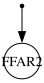

In [ ]:
graph_G4_solution.plot()

In [ ]:
for objective in problem_G4.objectives:
    print(objective.name, objective.value)

error_G4_KO_vs_WT_0 53.16548395780461
penalty_indirect_rules_0 [1.]
regularization_edge_has_signal 1.0


Diminuindo o max flow pra ver se o tempo diminui, pois naquele nao está conseguindo resolver a tempo

In [1]:
from corneto.methods import CarnivalFlow

carnival_G4 = CarnivalFlow(
    lambda_reg=1.0,
    indirect_rule_penalty=1,
    max_flow=50,
)

problem_G4 = carnival_G4.build(
    graph,
    data_G4,
)

ImportError: cannot import name 'CarnivalFlow' from 'corneto.methods' (/home/tahila/miniconda3/envs/scRNA_NEW_signaling/lib/python3.10/site-packages/corneto/methods/__init__.py)

# Outras células

In [ ]:
carnival_results = {}

for celltype, measurements in celltype_measurements_human.items():
    if celltype == "G4":
        # already run above
        continue

    print(f"\n=== {celltype} ===")

    try:
        reachability, graph_pruned = CheckCarnivalReachability(
            graph,
            perturbations,
            measurements,
        )

        carnival_data, measurements_used = BuildCarnivalData(
            graph_pruned,
            measurements,
            input_node="FFAR2",
            input_value=-1,
            sample_name=f"{celltype}_KO_vs_WT",
        )

        carnival, problem = BuildCarnivalProblem(
            graph_pruned,
            carnival_data,
            lambda_reg=1.0,
            indirect_rule_penalty=10,
        )

        problem = SolveCarnivalProblem(
            problem,
            solver="highs",
            max_seconds=60,
            verbosity=1,
        )

        graph_solution, edges, nodes = ExtractCarnivalSolution(
            carnival,
            problem,
        )

    except (ValueError, RuntimeError) as error:
        # e.g. no TF measurements left in the pruned PKN, or CARNIVAL
        # found no active signaling edges for this celltype -- skip it
        # instead of losing the celltypes already processed
        print(f"Skipped {celltype}: {error}")
        carnival_results[celltype] = {"error": str(error)}
        continue

    carnival_results[celltype] = {
        "reachability": reachability,
        "graph_pruned": graph_pruned,
        "carnival_data": carnival_data,
        "measurements_used": measurements_used,
        "carnival": carnival,
        "problem": problem,
        "graph_solution": graph_solution,
        "edges": edges,
        "nodes": nodes,
    }

carnival_results